In [6]:
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import joblib
import h5py
from scipy.spatial.distance import squareform
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DResult
from IPython.display import Image

## Example with experimental dataset

In contrast to our simulated dataset above, experimental ones are much more complex and also have low probe detection efficiencies. We can still use this to find meaningful information as long as proximity co-occurrence patterns exist latent in the data. For an example, here, we use a part of the tracing data from Bintu & Chen *et al.*, 2018, where we have an existing model

In [7]:
data_test_exp = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data_test_exp.shape

(1745, 946)

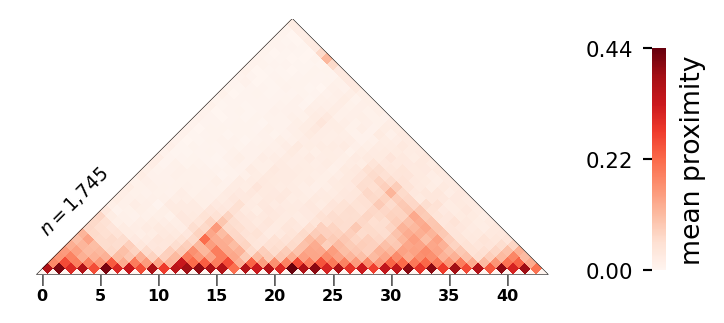

In [8]:
fig = data_test_exp.plot_ensemble_measure(method="mean", form="triangle", cbar_label="mean proximity")
fig.set_dpi(192)
fig.show()

Here, we will fit to and decompose the testing data

```bash
topic3d-decompose \
        --data_test_file ./data/sample_exp.npy \
        --results_dir ./results/ \
```

In [9]:
# subprocess.run([
#     "topic3d-decompose",
#     "--data_train_file", "./data/sample_exp_train.npy",
#     "--results_dir", "./results/",
#     "--num_components", "15",
#     "--max_iter", "200",
#     "--learning_method", "batch",
#     "--random_state", "42",
# ])

In [ ]:
subprocess.run([
    "topic3d-decompose",
    "--data_test_file", "./data/sample_exp.npy",
    "--model_file", "./models/model_exp.jl",
    "--results_dir", "./results/",
    "--num_components", "15",
    # "--max_iter", "200",
    # "--learning_method", "batch",
    # "--random_state", "42",
])

In [10]:
model = joblib.load(filename="./models/model_exp.jl")
model.bound_, model.perplexity(data_test_exp)

/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LatentDirichletAllocation from version 1.2.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


(np.float64(560.0640996041963), np.float64(640.5018537406993))

In [11]:
training_id = "a23231"      # needs to be set manually for now

Since the results get saved automatically at the end of the process, we can simply view the components and decomposition matrices.

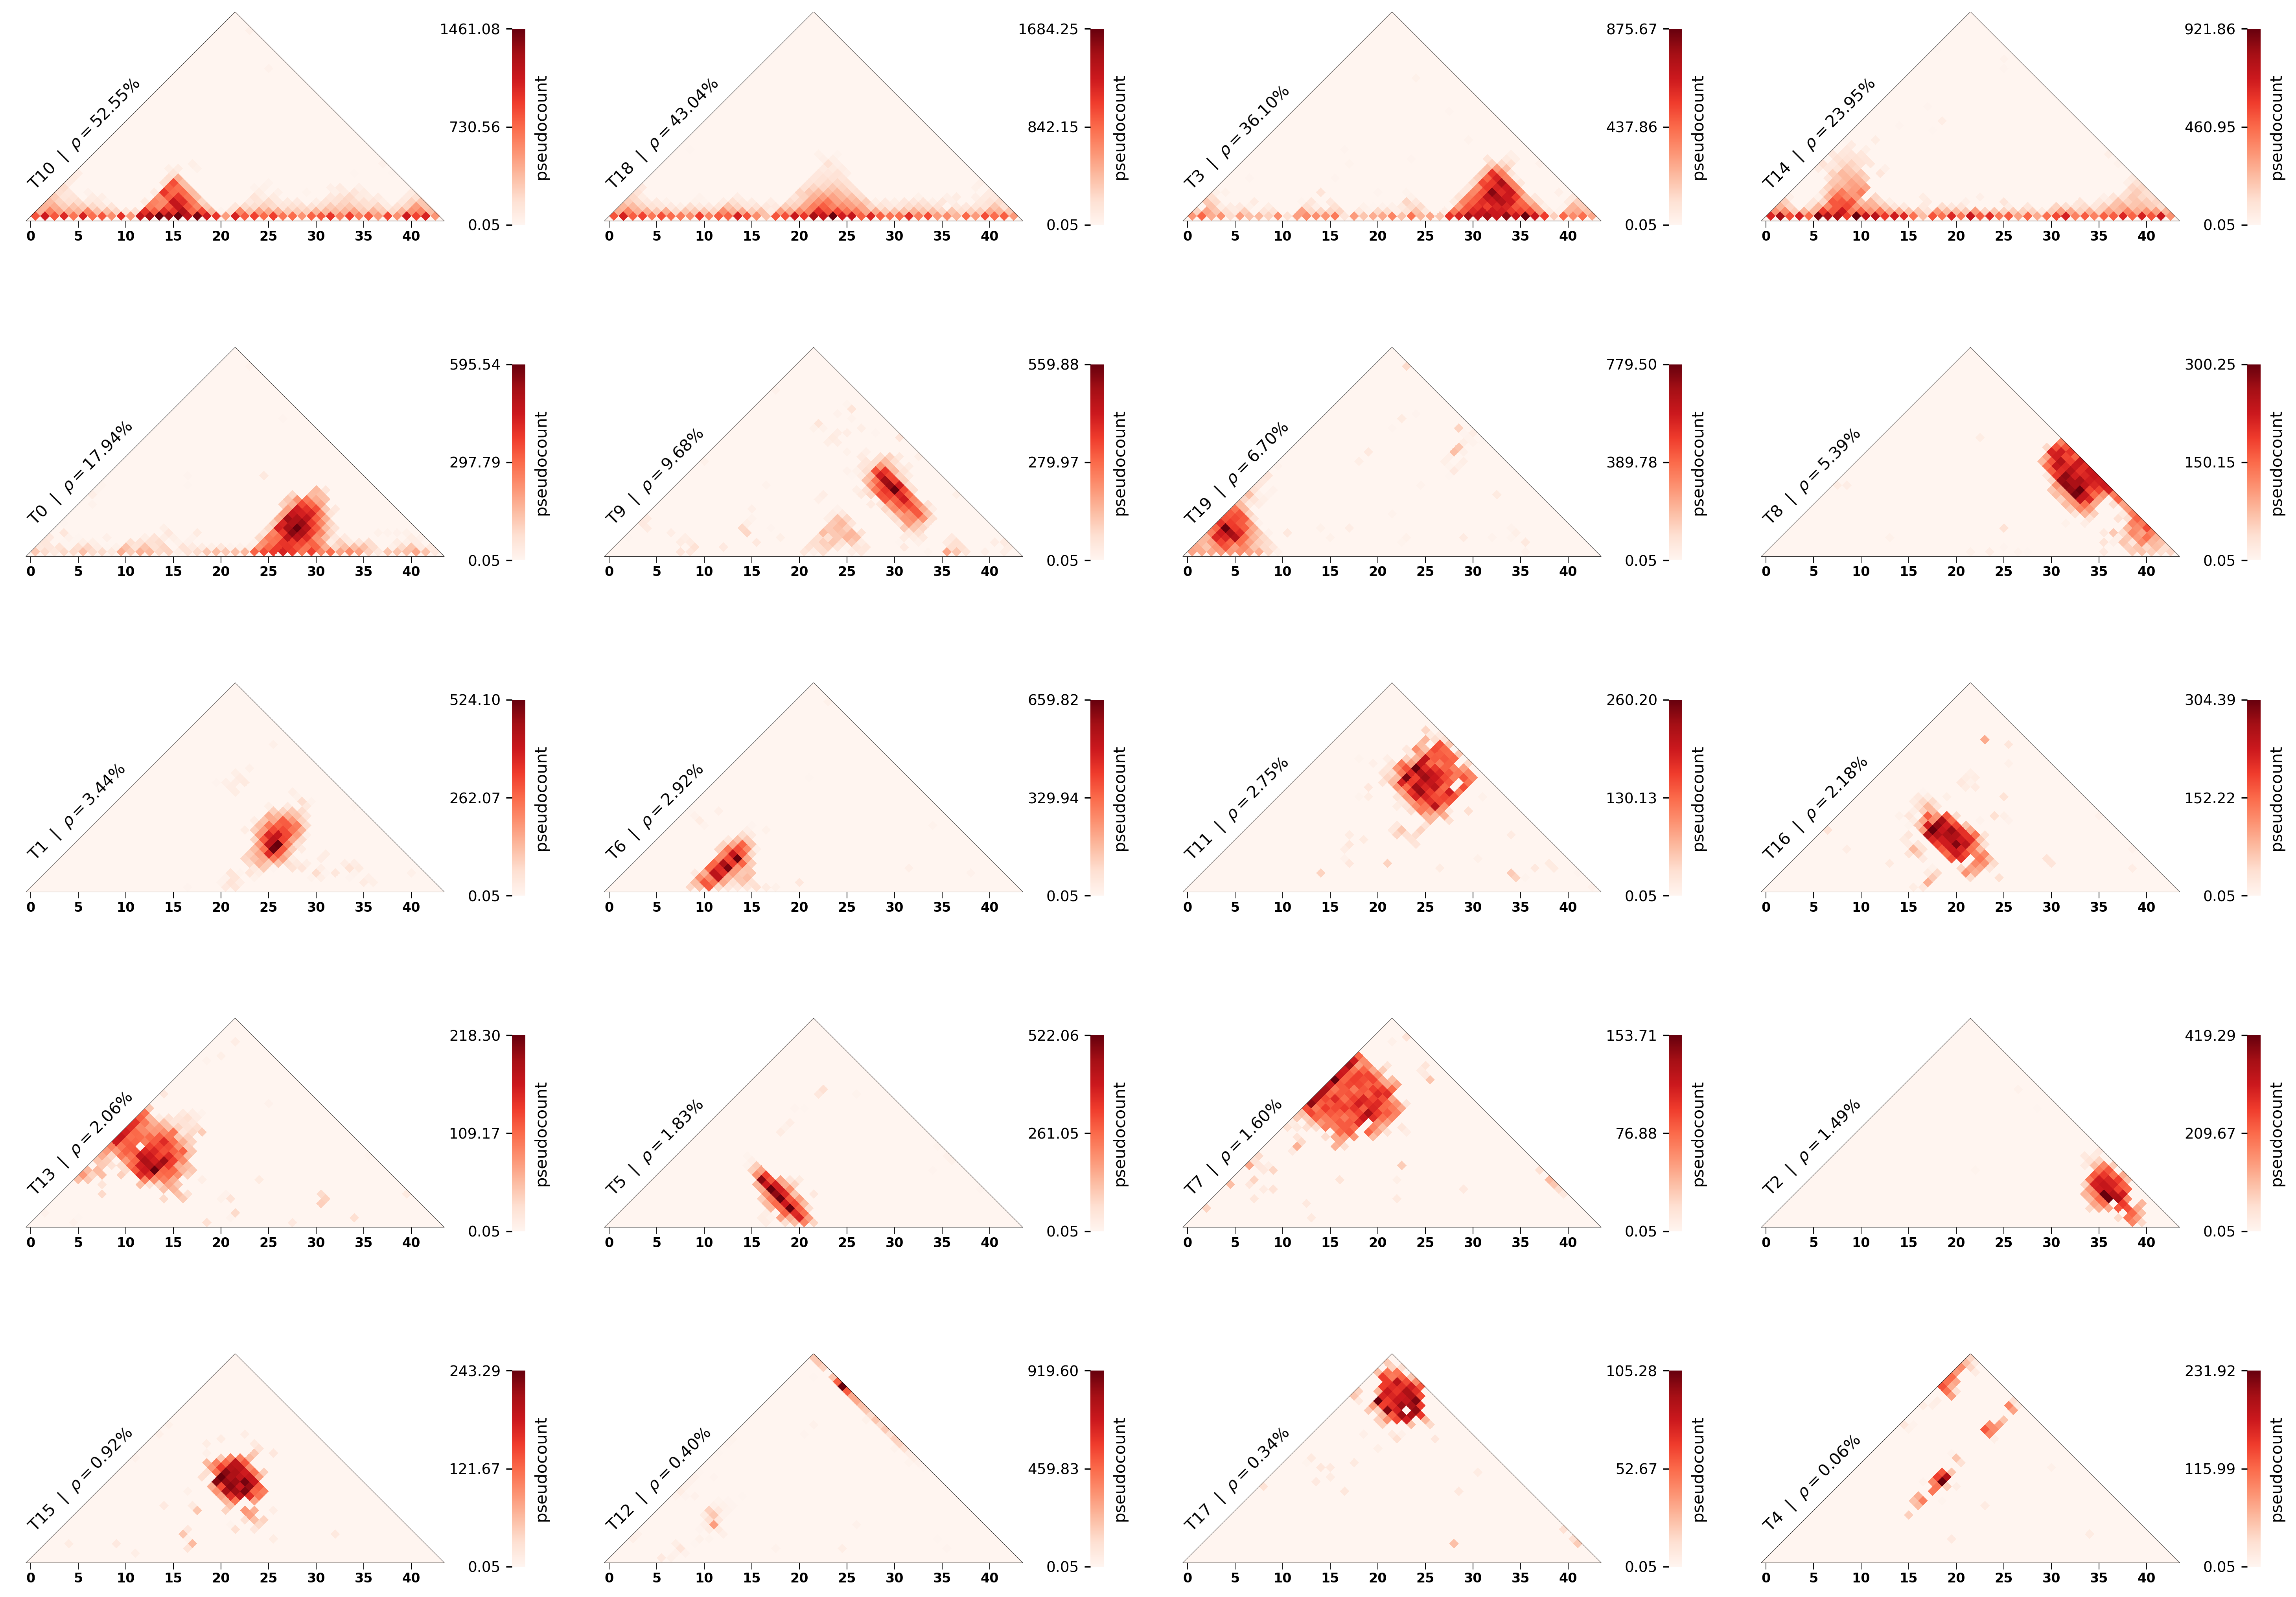

In [12]:
Image(filename=f"./results/{training_id}/components_sorted.png")

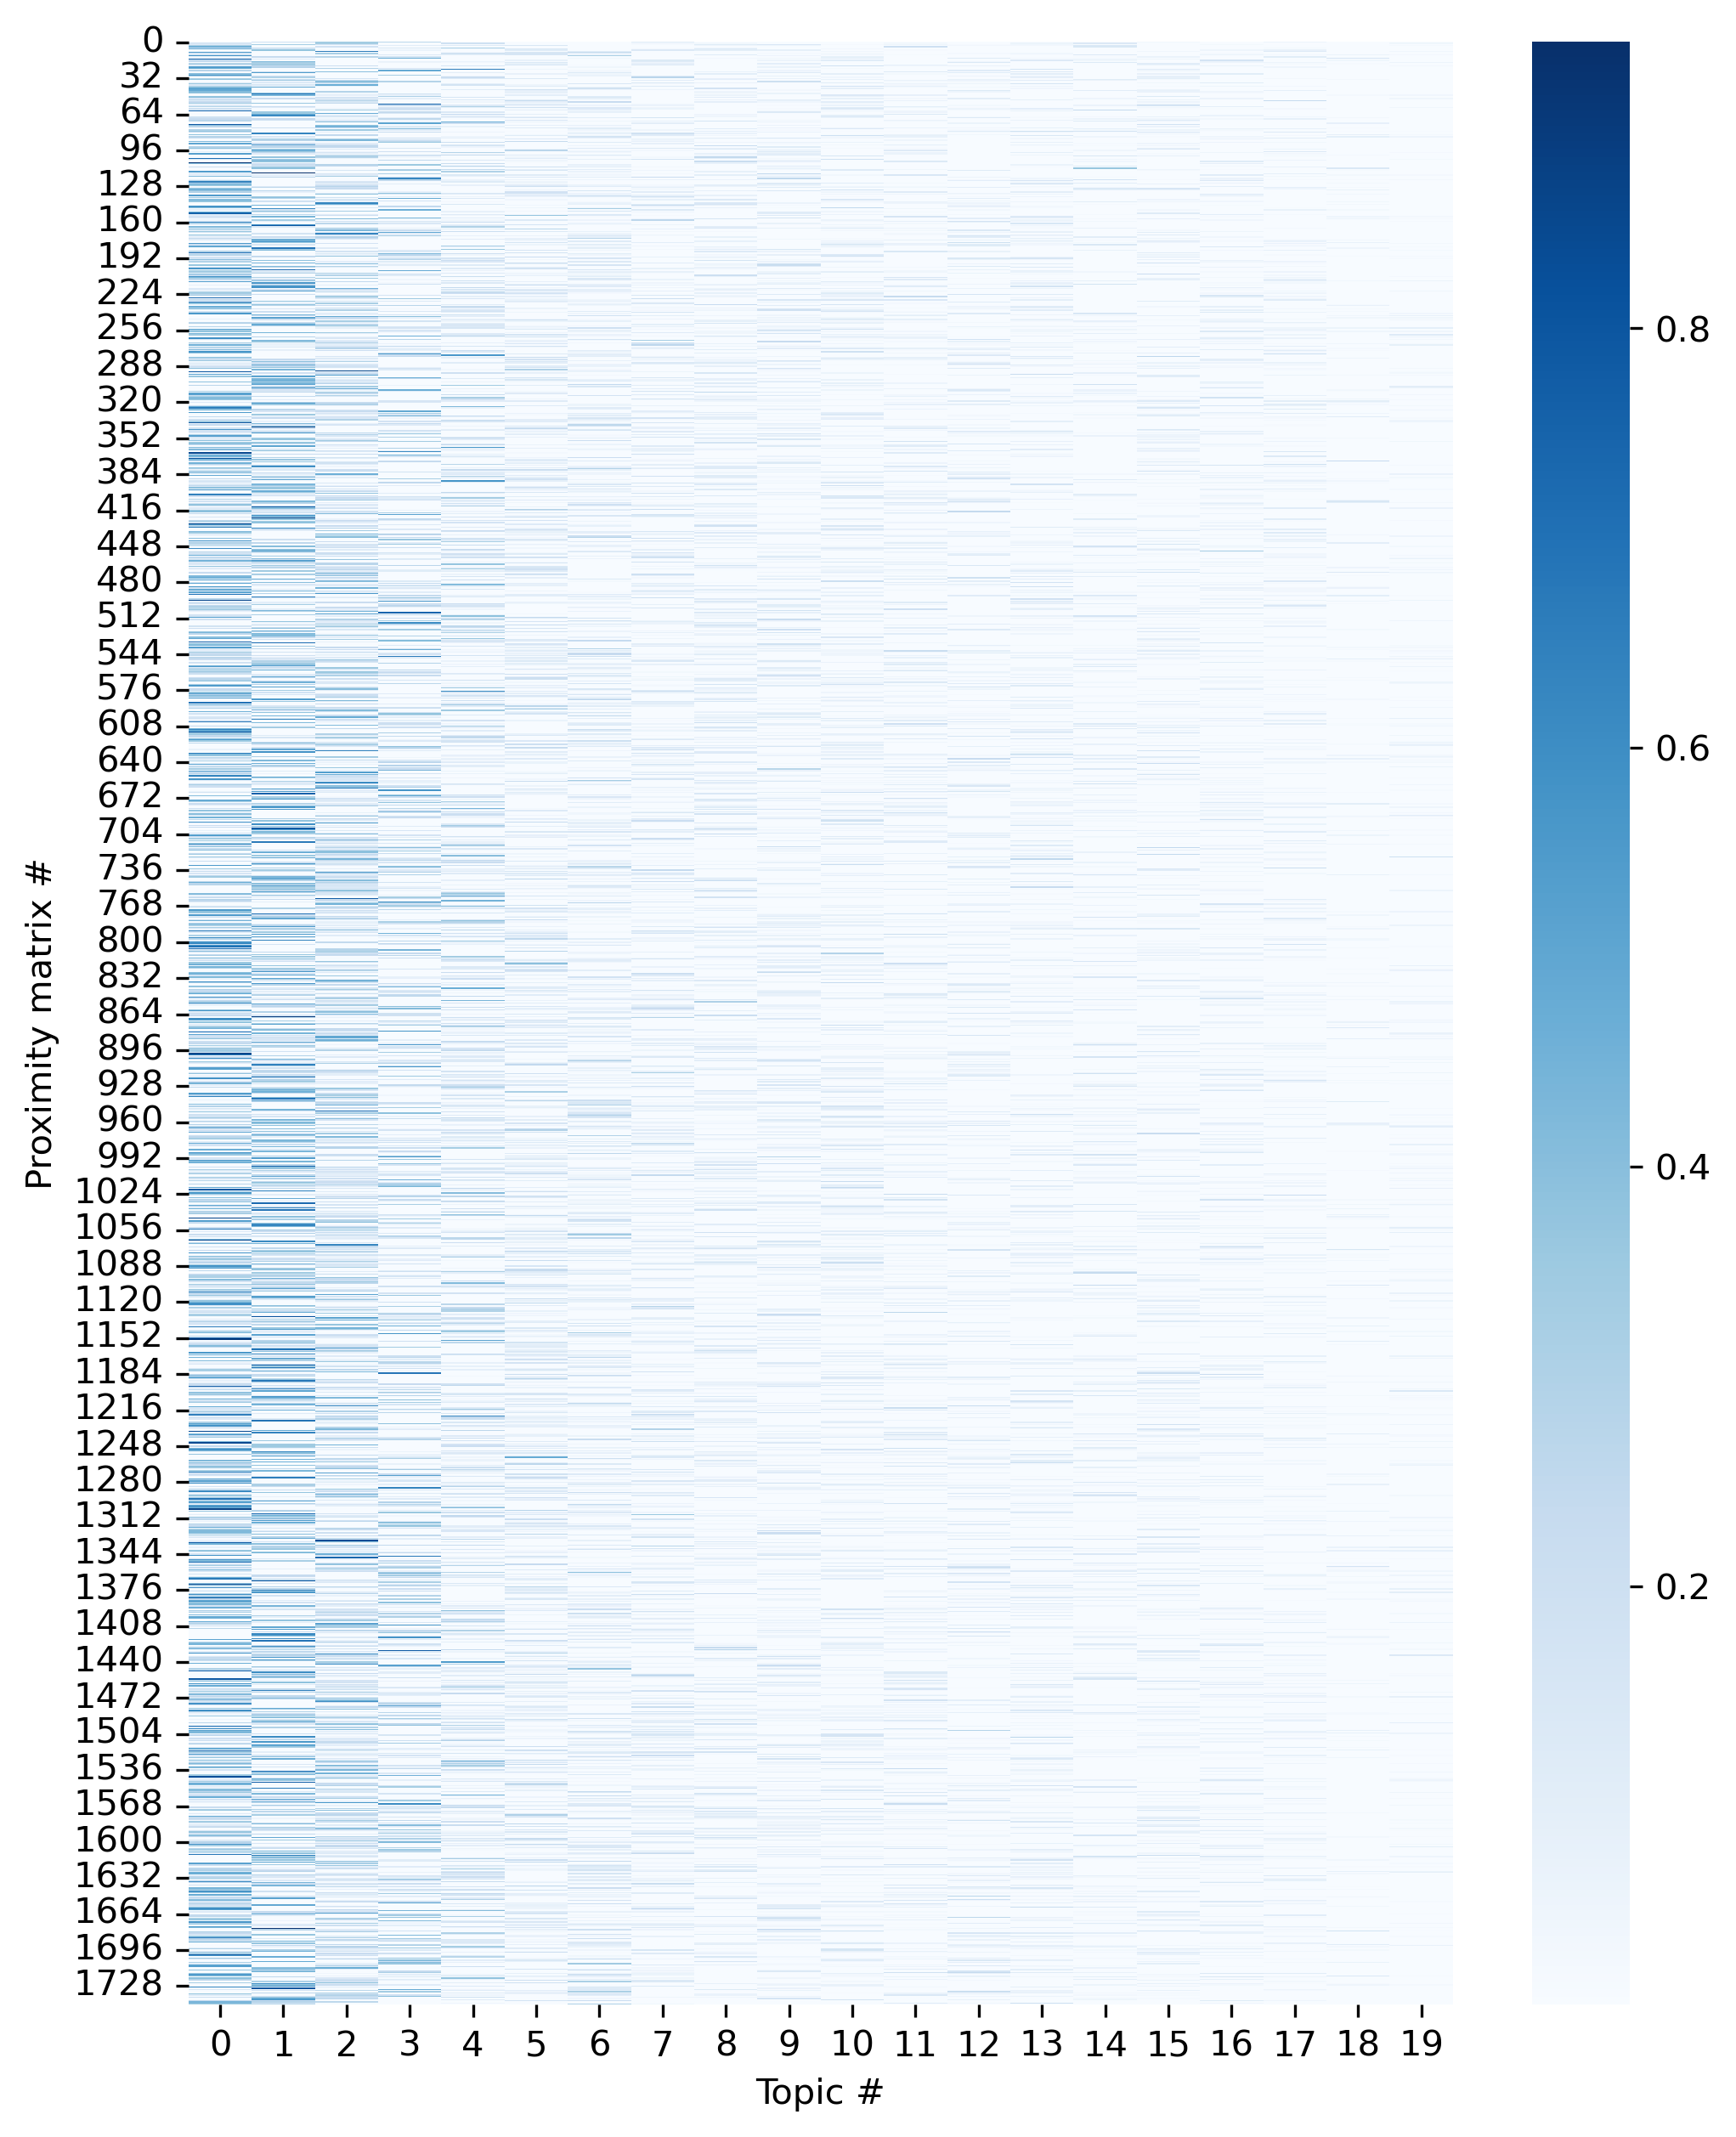

In [13]:
Image(filename=f"./results/{training_id}/decomposition.png", width=600, height=1600)

In [14]:
def hdf5_group_to_dict(h5obj):
    """
    Recursively convert an HDF5 group or file into a nested Python dictionary.

    Parameters
    ----------
    h5obj : h5py.Group or h5py.File
        HDF5 object to convert.

    Returns
    -------
    dict
        Nested dictionary representation of the HDF5 structure.
    """

    out = {}

    # Add attributes (if any)
    if hasattr(h5obj, "attrs") and len(h5obj.attrs) > 0:
        out["_attrs"] = {k: v for k, v in h5obj.attrs.items()}

    for key, item in h5obj.items():

        # If subgroup → recurse
        if isinstance(item, h5py.Group):
            out[key] = hdf5_group_to_dict(item)

        # If dataset → extract data
        elif isinstance(item, h5py.Dataset):
            data = item[()]

            # Convert bytes to string if needed
            if isinstance(data, bytes):
                data = data.decode("utf-8")

            # Convert scalar numpy types to Python types
            if isinstance(data, np.generic):
                data = data.item()

            out[key] = data

    return out

To see which single-cell traces are similar in their classification into each topic, we can also embed them 

In [15]:
with h5py.File(f"./results/{training_id}/results.h5", mode="r") as handler:
    decomposition = handler["decomposition"][:]
    # coherence = hdf5_group_to_dict(handler["coherence"])
results = Topic3DResult(model=model, decomposition=decomposition)

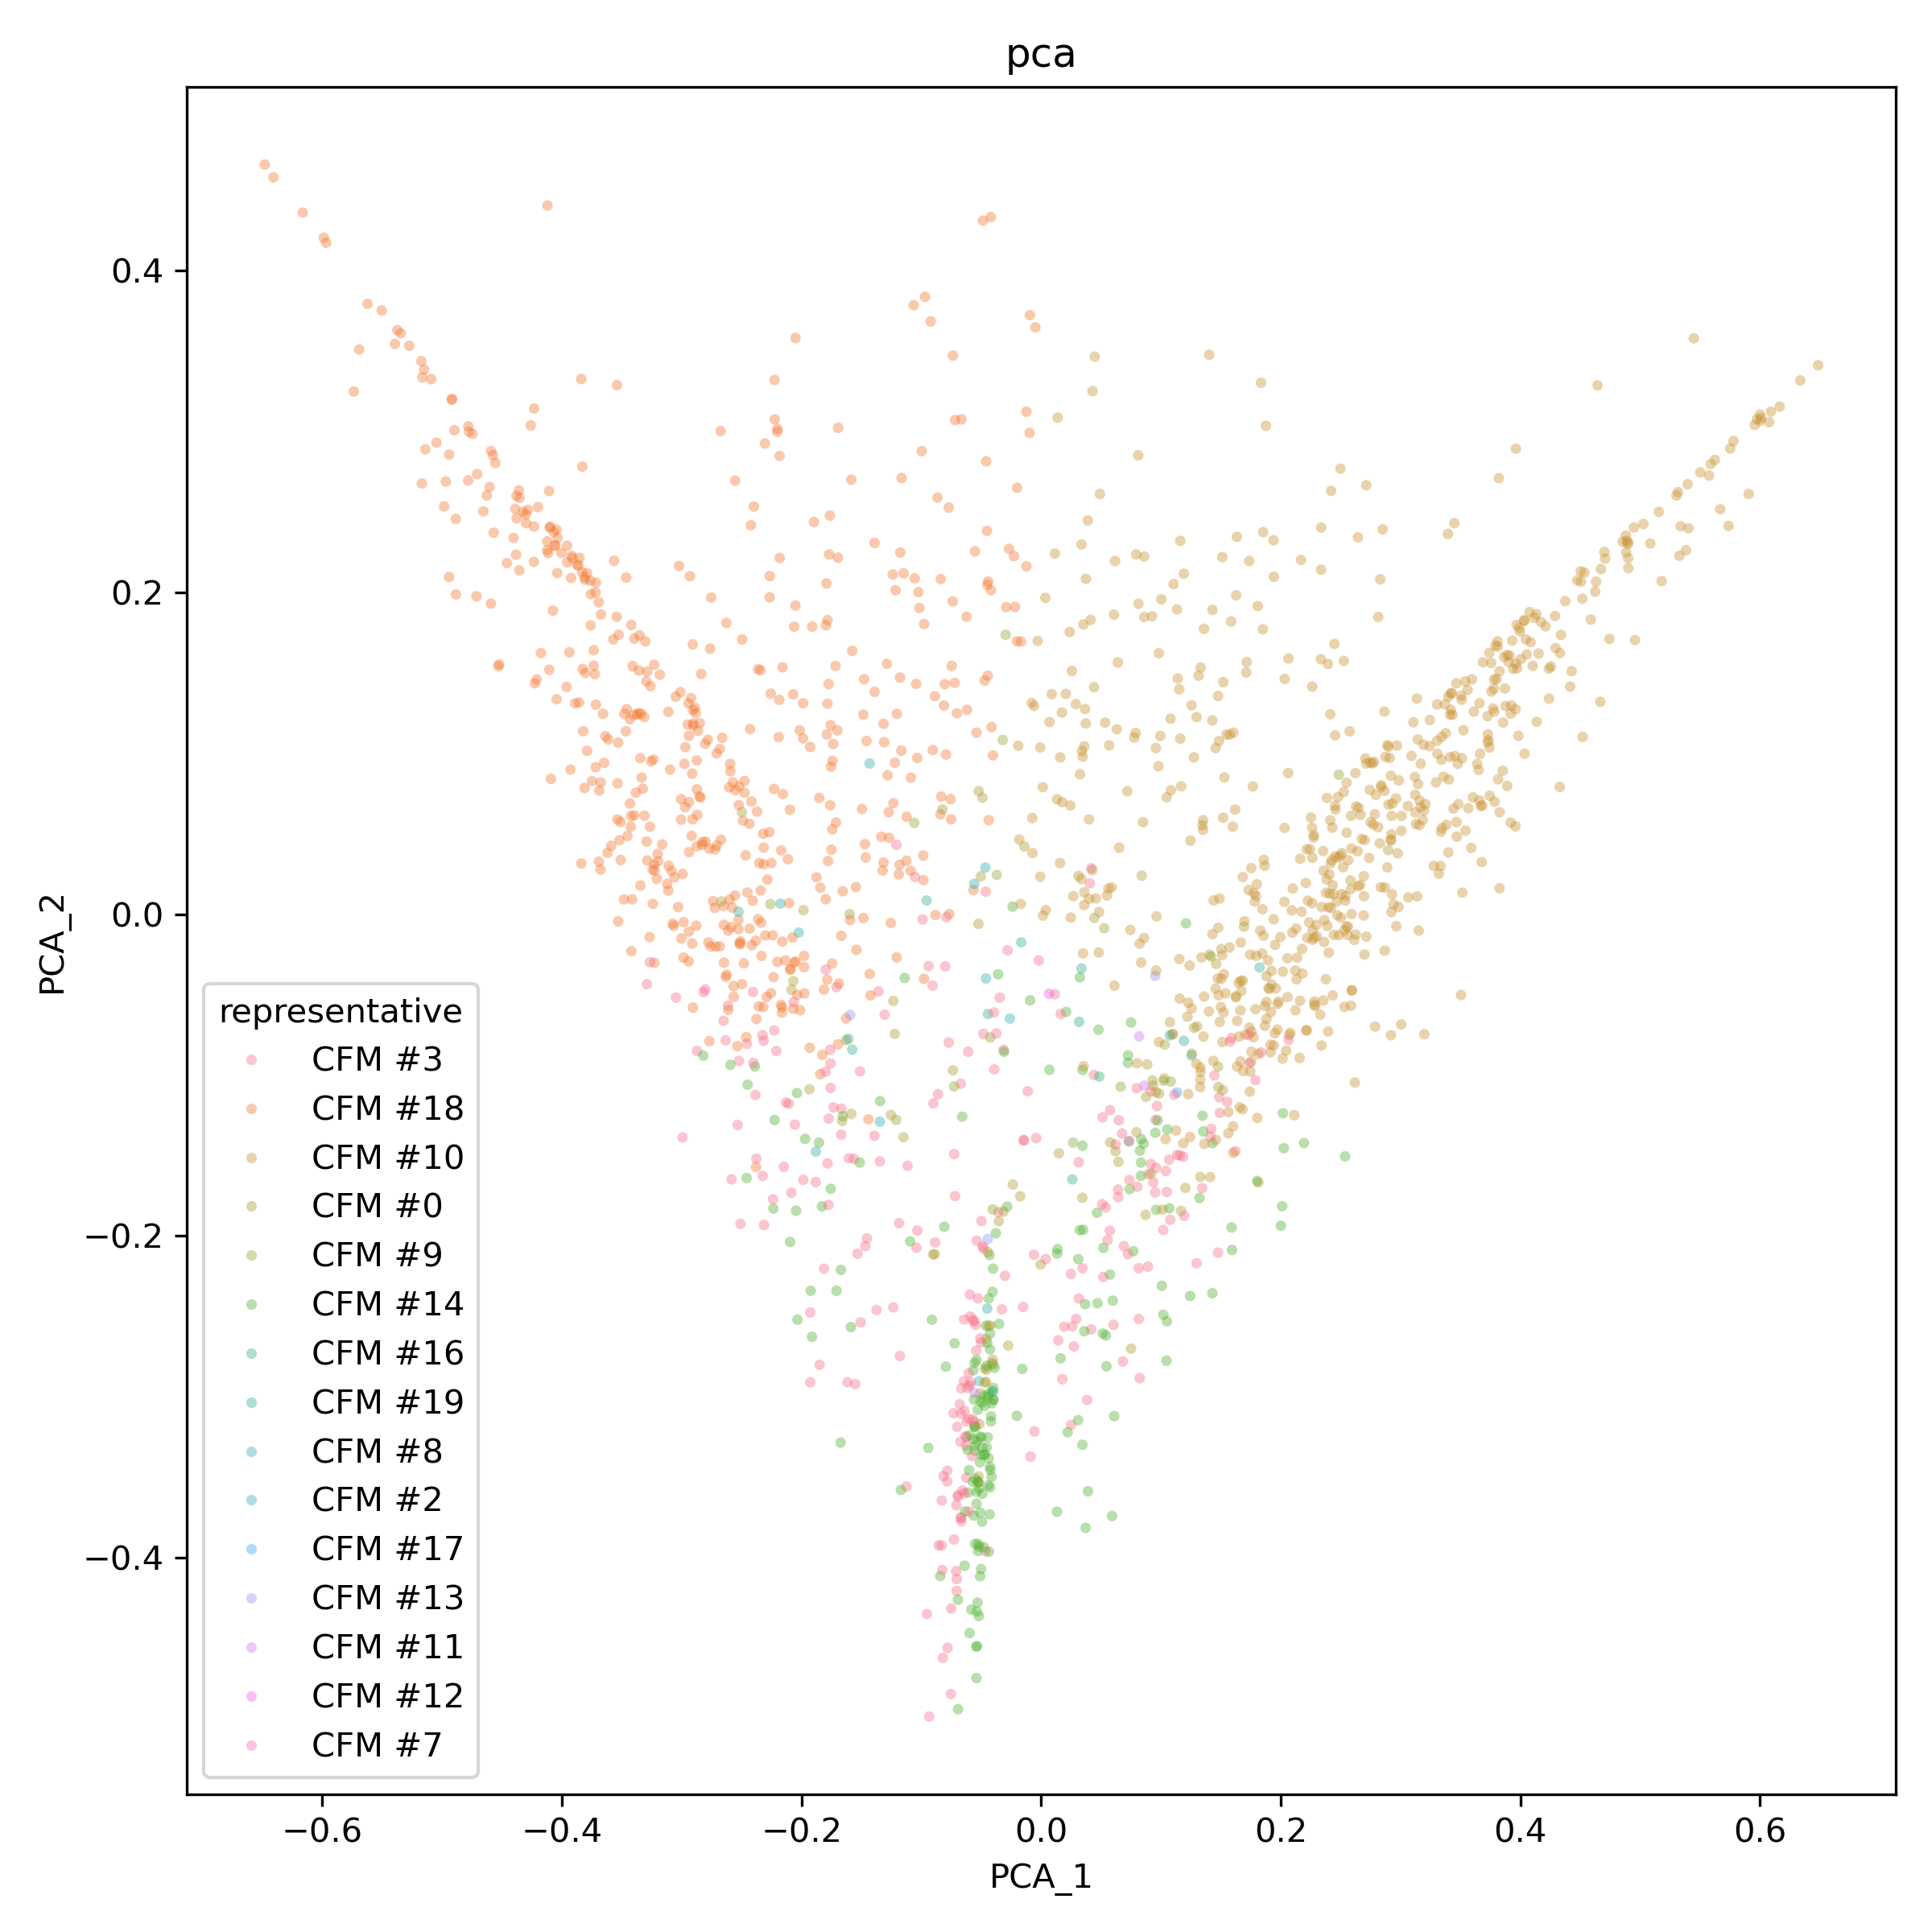

In [16]:
# TODO colour it by topic number with highest prob assignment
_ = results.embed_decomposition(dir_to_save=f"./results/{training_id}/",
                                method="PCA",
                                cluster=False,
                                save_models=True,)
Image(filename=f"./results/{training_id}/embedding_decomposition_pca.png")

In [18]:
params_UMAP = {"num_neighbors": 100,
               "min_dist": 0.05,
               "metric": "jensenshannon"}
params_HDBSCAN = {"min_cluster_size": 50,
                  "min_samples": 1,
                  "cluster_selection_method": "leaf",
                  "alpha": 1.0,}
embedding = results.embed_decomposition(dir_to_save=f"./results/{training_id}/",
                                        method="UMAP",
                                        cluster=True,
                                        save_models=True,
                                        **params_UMAP, 
                                        **params_HDBSCAN)

/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


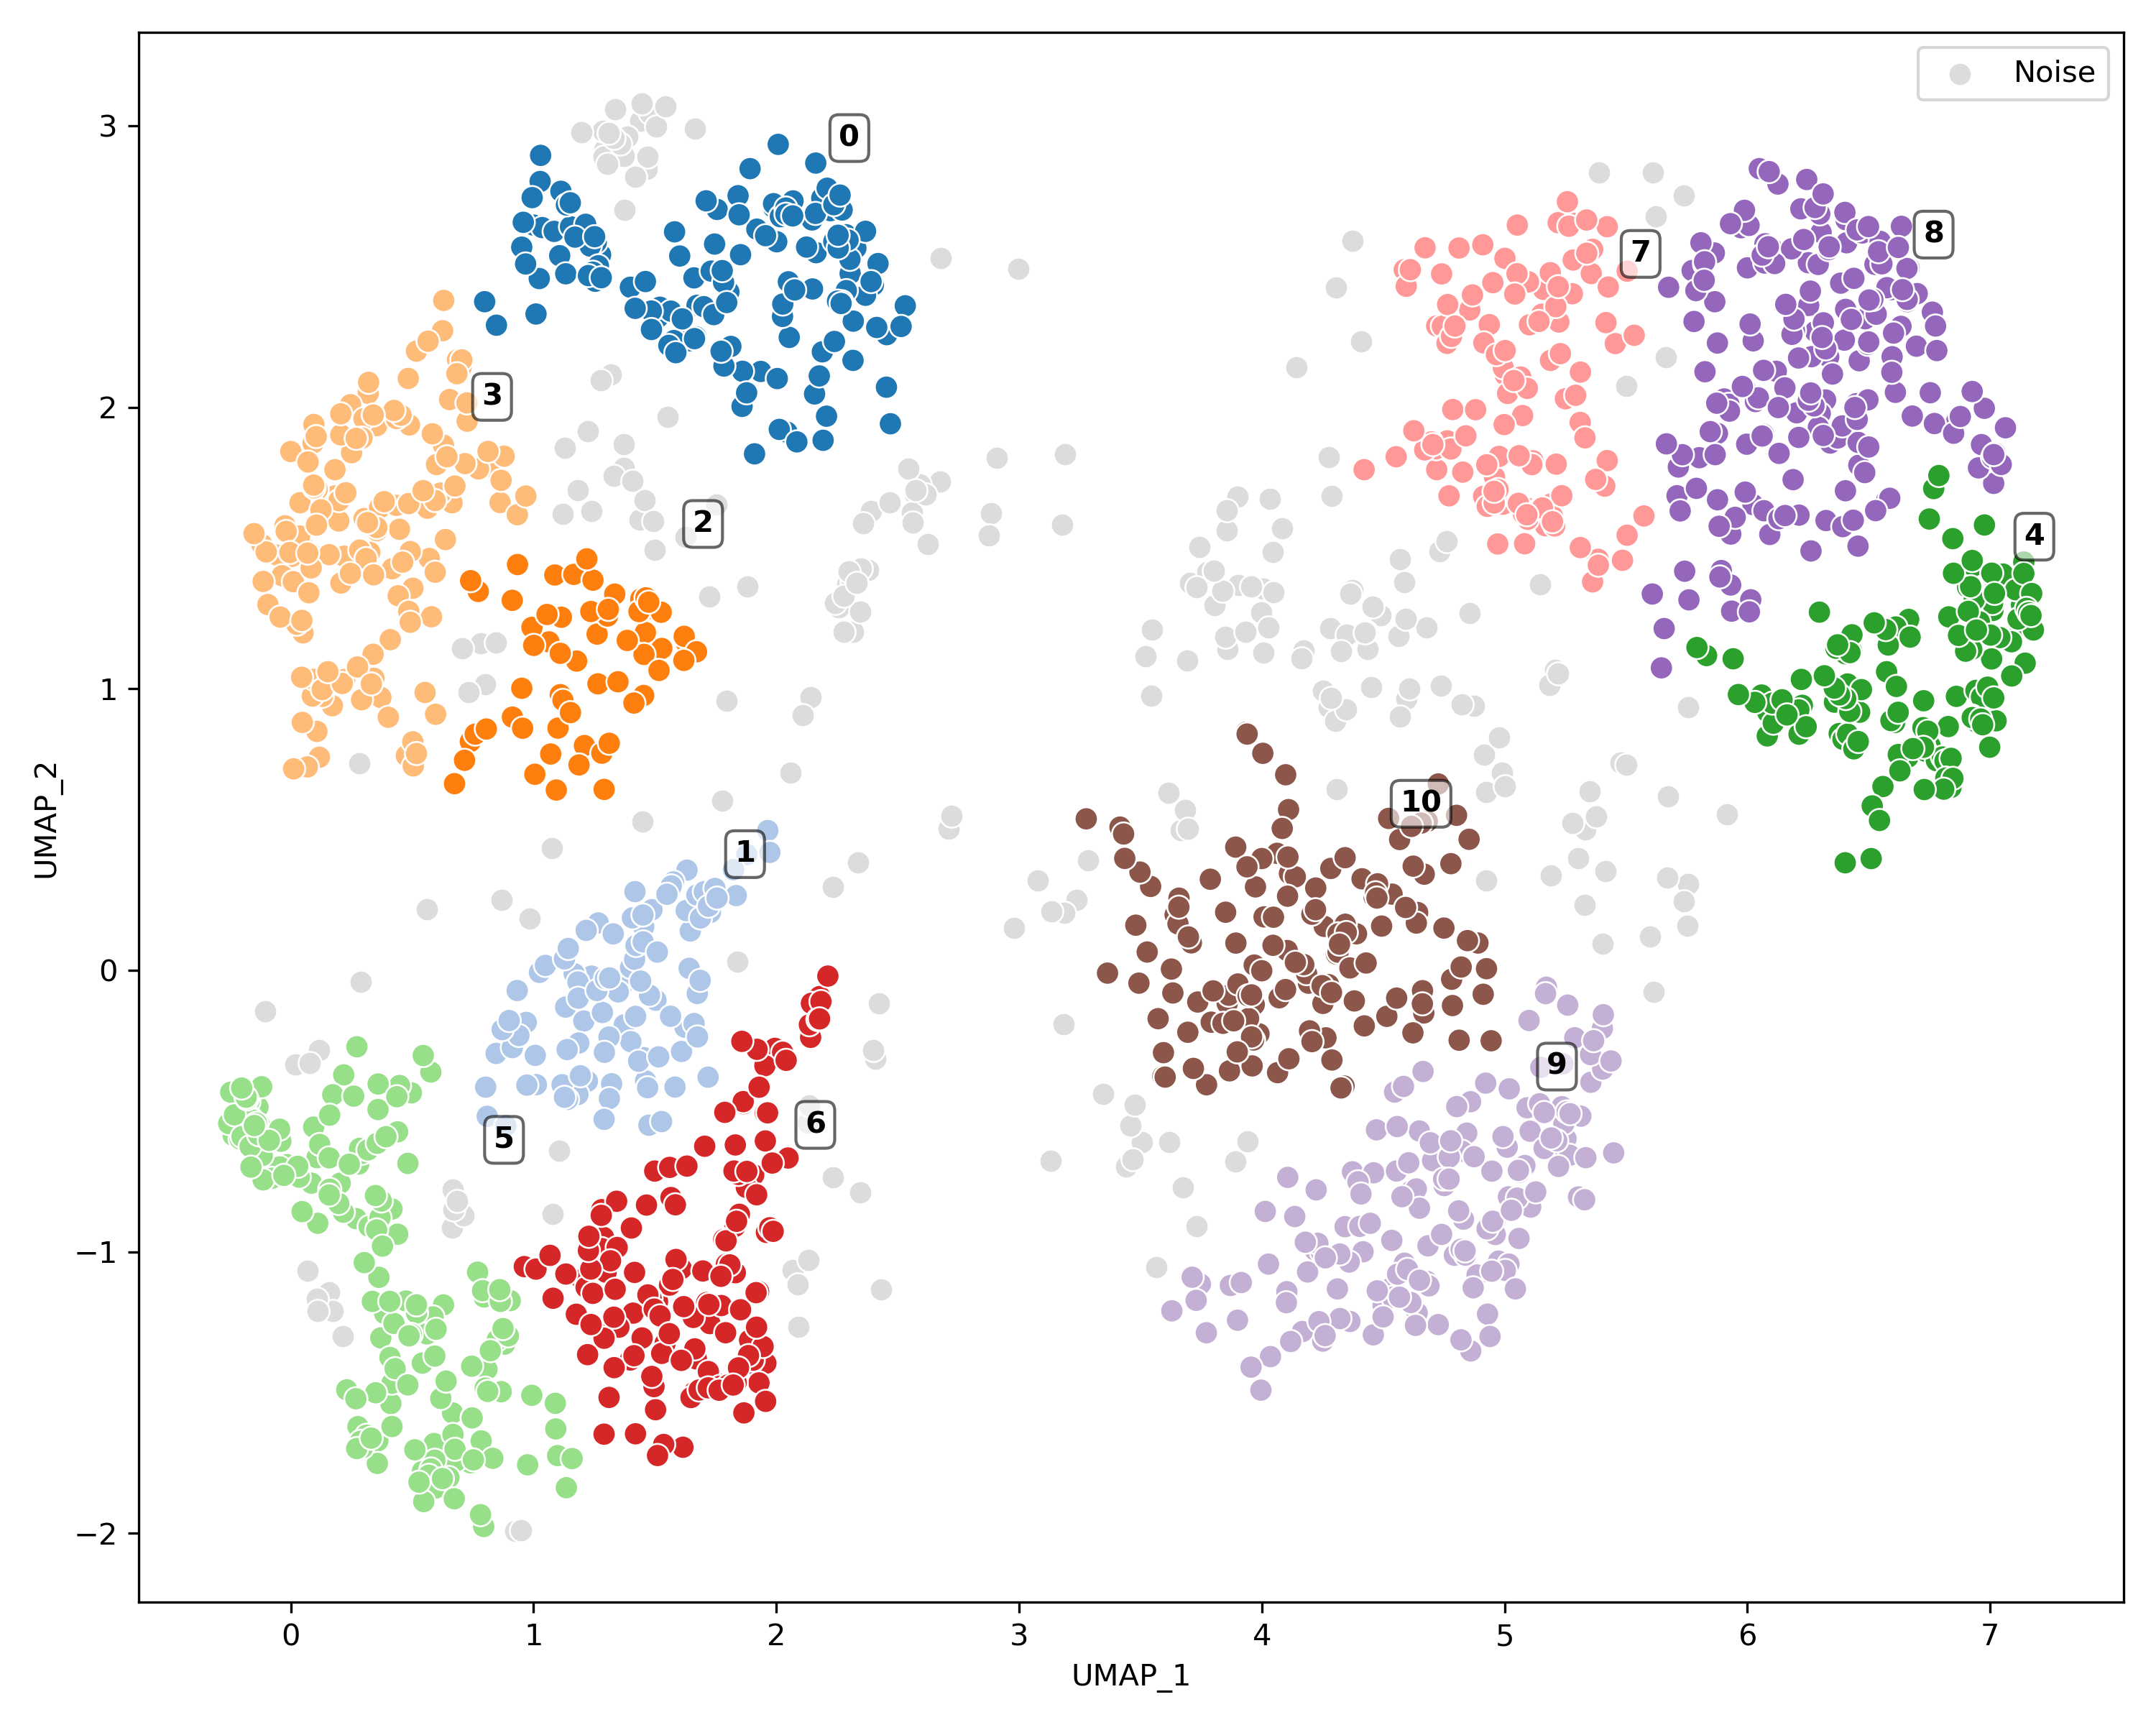

In [ ]:
Image(filename=f"./results/{training_id}/embedding_decomposition_umap_clustered.png")

In [111]:
embedding.head()

,UMAP_1,UMAP_2,cluster
0,4.910136,2.577236,7
1,1.728390,0.205898,1
2,4.306913,0.057997,10
3,0.570627,1.462977,3
4,1.726149,-1.472369,6


In [112]:
clusters = embedding["cluster"].unique()
clusters.sort()
clusters = clusters[1:]
clusters

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [113]:
prox_mats_by_cluster = [data_test_exp[embedding.loc[embedding["cluster"] == cluster].index] \
                        for cluster in clusters]

In [ ]:
prox_avg_by_cluster = [mat.compute_ensemble_measure(method="mean") for mat in prox_mats_by_cluster]

In [115]:
from topic3d.visualization import plot_matrices_triangle

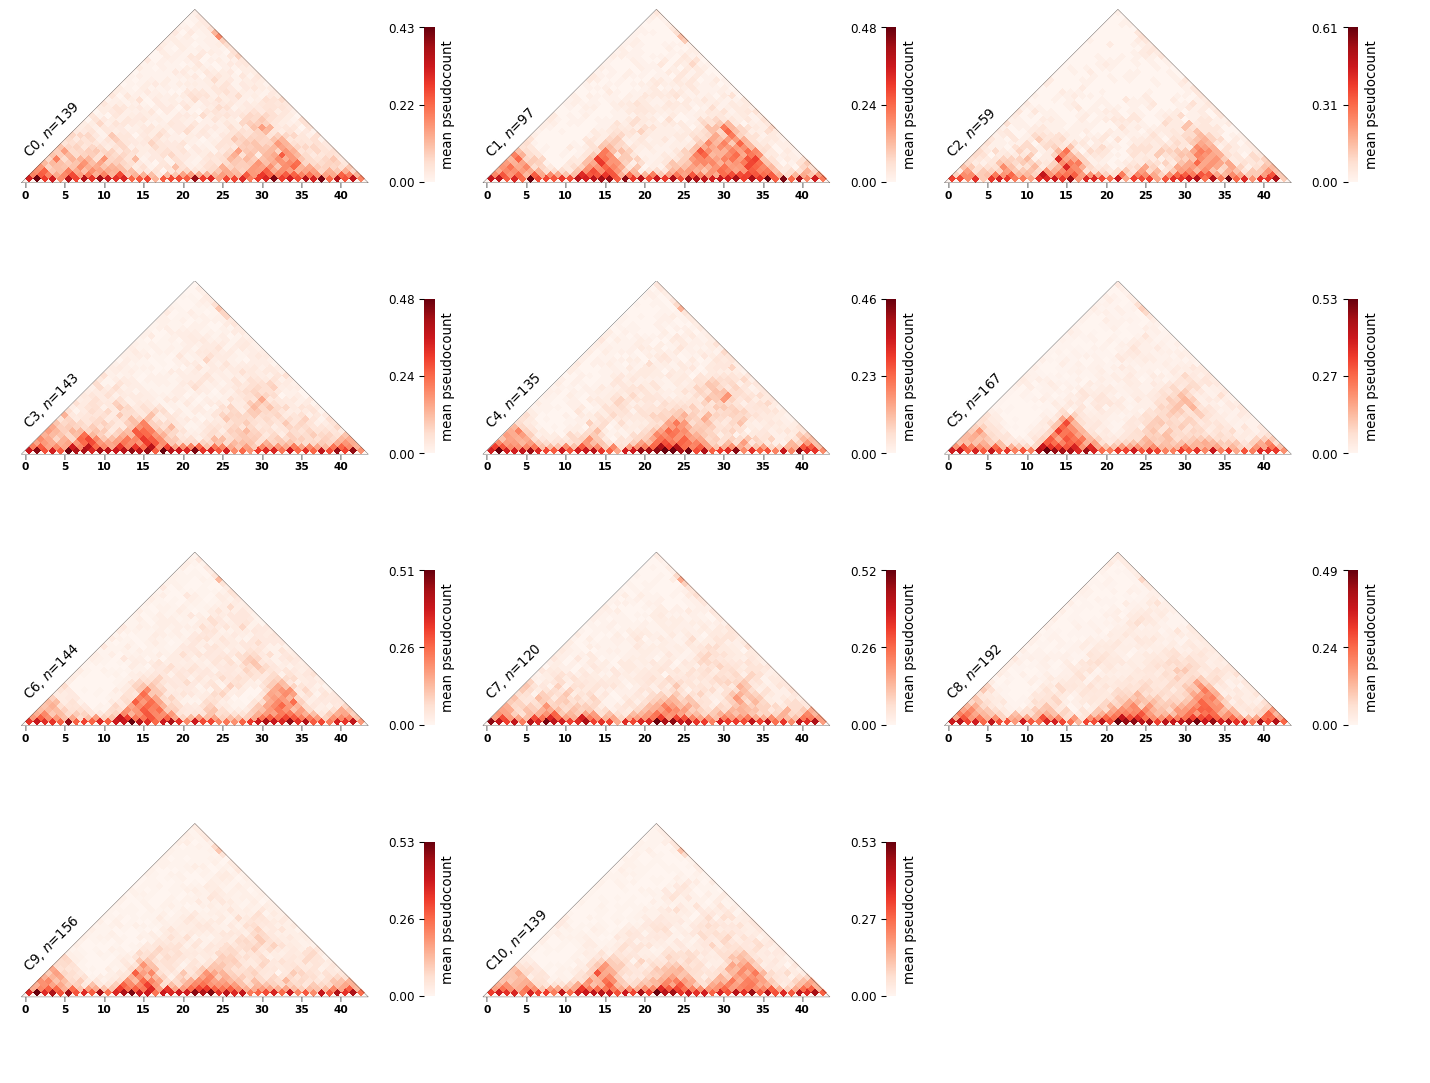

In [116]:
fig = plot_matrices_triangle(items=prox_avg_by_cluster,
                             titles=[f"C{cluster}, $n$={len(prox_mats_by_cluster[i])}" \
                                     for i, cluster in enumerate(clusters)],
                             cbar_label="mean pseudocount")
fig.set_dpi(96)
fig.show()